# CIFAR-10 Deep Learning Experiments

This notebook explores how different neural-network design choices affect image classification on CIFAR-10.

The experiments progress from fully connected baselines to convolutional feature extraction and finally to frozen-backbone feature reuse for a binary **Horse vs. Not-Horse** task.

## Experiments

- Dense baseline with ReLU + He initialization
- Batch Normalization placement: after vs. before ReLU
- SELU + LeCun Normal initialization
- Simple convolution-filter visualization
- Custom 6-layer CNN for CIFAR-10
- Frozen CNN backbone for Horse vs. Not-Horse classification

## 1. Setup

All paths are relative to the project directory so the notebook can run on another machine after cloning the repository.

In [ ]:
import tensorflow as tf
from tensorflow import keras

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import StandardScaler


In [3]:
keras.utils.set_random_seed(42)

In [1]:
from pathlib import Path

MODEL_DIR = Path("models")
HISTORY_DIR = Path("histories")

## 2. Dataset and preprocessing

CIFAR-10 contains 60,000 RGB images of size 32×32 across 10 classes.  
The official test set is kept separate from the training/validation split and is used only for final evaluation.

Pixel values are scaled once to the `[0, 1]` range.

In [4]:
import tarfile

file_path = r"D:\cifar\cifar-10-python.tar.gz"
extract_path = r"D:\cifar"

with tarfile.open(file_path, "r:gz") as tar:
    tar.extractall(extract_path)

print("Done!")

Done!


In [5]:
import os

print(os.listdir(r"D:\cifar"))

['cifar-10-batches-py', 'cifar-10-python.tar.gz']


In [6]:
import pickle
import numpy as np
data_path = r"D:\cifar\cifar-10-batches-py"

In [7]:
def load_batch(file):
    with open(file, "rb") as f:
        data = pickle.load(f, encoding="bytes")
    
    x = data[b"data"]
    y = data[b"labels"]
    
    return x, y

In [48]:
x_train_list = []
y_train_list = []

for i in range(1, 6):
    x, y = load_batch(
        rf"{data_path}\data_batch_{i}"
    )
    
    x_train_list.append(x)
    y_train_list.extend(y)

x_train = np.concatenate(x_train_list, axis=0)
y_train = np.array(y_train_list)

In [49]:
x_test, y_test = load_batch(
    rf"{data_path}\test_batch"
)

y_test = np.array(y_test)

In [10]:
x_test.shape

(10000, 3072)

In [50]:
x_train1 = x_train.reshape(-1, 3, 32, 32)
x_train2 = x_train1.transpose(0, 2, 3, 1)

x_test1 = x_test.reshape(-1, 3, 32, 32)
x_test2 = x_test1.transpose(0, 2, 3, 1)

print(x_train2.shape)
print(x_test2.shape)

(50000, 32, 32, 3)
(10000, 32, 32, 3)


In [51]:
x_train = x_train2.astype("float32") / 255.0
x_test = x_test2.astype("float32") / 255.0

## 3. Fully connected baseline — ReLU + He initialization

This model deliberately flattens the image and therefore discards explicit spatial structure. It acts as a baseline for comparison with the later CNN.

In [13]:
keras.utils.set_random_seed(42)

In [ ]:
relu_baseline = keras.models.Sequential([
    keras.layers.Flatten(input_shape=[32, 32, 3]),
    keras.layers.Dense(50, kernel_initializer="he_normal", activation="relu", use_bias=False),
    keras.layers.Dense(50, kernel_initializer="he_normal", activation="relu",  use_bias=False),
    keras.layers.Dense(10, activation="softmax")
])

In [ ]:
relu_baseline.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_1 (Flatten)         (None, 3072)              0         
                                                                 
 dense_3 (Dense)             (None, 50)                153600    
                                                                 
 dense_4 (Dense)             (None, 50)                2500      
                                                                 
 dense_5 (Dense)             (None, 10)                510       
                                                                 
Total params: 156,610
Trainable params: 156,610
Non-trainable params: 0
_________________________________________________________________


In [ ]:
W1_before = relu_baseline.layers[1].get_weights()
W2_before = relu_baseline.layers[2].get_weights()

print("W1 unique:", np.unique(W1_before))
print("W2 unique:", np.unique(W2_before))

W1 unique: [-0.05801174 -0.0580077  -0.05800705 ...  0.05800133  0.05800353
  0.05800381]
W2 unique: [-0.45176533 -0.44994152 -0.44944355 ...  0.4470461   0.4481698
  0.44896188]


In [ ]:
relu_baseline.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics="accuracy",

)

In [37]:
from sklearn.model_selection import train_test_split
import numpy as np

x_tr, x_val, y_tr, y_val = train_test_split(x_train, y_train, test_size=0.2, stratify=y_train.reshape(-1), random_state=42)

In [ ]:
history_relu = relu_baseline.fit(
    x_tr,
    y_tr,
    epochs=50,
    batch_size=64,
    validation_data=(x_val, y_val)
)

Epoch 1/50
625/625 [==============================] - 9s 9ms/step - loss: 1.9939 - accuracy: 0.2625 - val_loss: 1.8735 - val_accuracy: 0.3234
Epoch 2/50
625/625 [==============================] - 3s 5ms/step - loss: 1.8820 - accuracy: 0.3091 - val_loss: 1.8700 - val_accuracy: 0.3145
Epoch 3/50
625/625 [==============================] - 3s 5ms/step - loss: 1.8597 - accuracy: 0.3149 - val_loss: 1.8347 - val_accuracy: 0.3304
Epoch 4/50
625/625 [==============================] - 3s 5ms/step - loss: 1.8332 - accuracy: 0.3241 - val_loss: 1.8035 - val_accuracy: 0.3363
Epoch 5/50
625/625 [==============================] - 3s 5ms/step - loss: 1.8194 - accuracy: 0.3352 - val_loss: 1.7995 - val_accuracy: 0.3397
Epoch 6/50
625/625 [==============================] - 3s 5ms/step - loss: 1.8104 - accuracy: 0.3374 - val_loss: 1.8104 - val_accuracy: 0.3323
Epoch 7/50
625/625 [==============================] - 4s 6ms/step - loss: 1.8014 - accuracy: 0.3401 - val_loss: 1.7937 - val_accuracy: 0.3443
Epoch 

In [ ]:
import numpy as np

np.savez(
    file_path=HISTORY_DIR/ "history_relu",
    **history_relu.history
)

## 4. Batch Normalization placement

Two related networks are compared:

1. **BN after ReLU** — activation is applied inside each Dense layer and Batch Normalization follows it.
2. **BN before ReLU** — Dense is linear, then Batch Normalization is applied, followed by a separate ReLU activation.

The same train/validation split is used for both models.

In [ ]:
import keras
model_relu_before_bn = keras.models.Sequential([
    keras.layers.Flatten(input_shape=[32, 32, 3]),
    keras.layers.BatchNormalization(),
    keras.layers.Dense(50, kernel_initializer="he_normal", activation="relu", use_bias=False),
    keras.layers.BatchNormalization(),
    keras.layers.Dense(50, kernel_initializer="he_normal", activation="relu",  use_bias=False),
    keras.layers.BatchNormalization(),
    keras.layers.Dense(10, activation="softmax")
])

In [ ]:
model_relu_before_bn.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics="accuracy",

)

In [ ]:
history_relu_before_bn = model_relu_before_bn.fit(
    x_tr,
    y_tr,
    epochs=50,
    batch_size=64,
    validation_data=(x_val, y_val)
)

Epoch 1/50
625/625 [==============================] - 15s 16ms/step - loss: 1.7724 - accuracy: 0.3728 - val_loss: 1.6069 - val_accuracy: 0.4278
Epoch 2/50
625/625 [==============================] - 5s 8ms/step - loss: 1.5761 - accuracy: 0.4418 - val_loss: 1.5465 - val_accuracy: 0.4562
Epoch 3/50
625/625 [==============================] - 8s 12ms/step - loss: 1.4907 - accuracy: 0.4742 - val_loss: 1.4978 - val_accuracy: 0.4665
Epoch 4/50
625/625 [==============================] - 7s 12ms/step - loss: 1.4435 - accuracy: 0.4885 - val_loss: 1.4673 - val_accuracy: 0.4817
Epoch 5/50
625/625 [==============================] - 8s 13ms/step - loss: 1.3993 - accuracy: 0.5027 - val_loss: 1.4532 - val_accuracy: 0.4800
Epoch 6/50
625/625 [==============================] - 8s 13ms/step - loss: 1.3674 - accuracy: 0.5161 - val_loss: 1.4466 - val_accuracy: 0.4873
Epoch 7/50
625/625 [==============================] - 6s 10ms/step - loss: 1.3375 - accuracy: 0.5265 - val_loss: 1.4237 - val_accuracy: 0.4960

In [ ]:
import numpy as np

np.savez(
    file_path=HISTORY_DIR/ "history_relu_before_bn",
    **history_relu_before_bn.history
)

## 5. Self-normalizing network — SELU + LeCun Normal

SELU is paired with LeCun Normal initialization.  
Unlike the original notebook, this model uses the same validation split as the other baselines; the test set is not used during training.

In [ ]:
import keras
model_relu_after_bn = keras.models.Sequential([
    keras.layers.Flatten(input_shape=[32, 32, 3]),
    keras.layers.BatchNormalization(),
    keras.layers.Dense(50, kernel_initializer="he_normal", use_bias=False),
    keras.layers.BatchNormalization(),
    keras.layers.Activation("relu"),
    keras.layers.Dense(50, kernel_initializer="he_normal",  use_bias=False),
    keras.layers.BatchNormalization(),
    keras.layers.Activation("relu"),
    keras.layers.Dense(10, activation="softmax")
])

In [ ]:
model_relu_after_bn.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics="accuracy",

)

In [ ]:
history_relu_after_bn = model_relu_after_bn.fit(
    x_tr,
    y_tr,
    epochs=50,
    batch_size=64,
    validation_data=(x_val, y_val)
)

Epoch 1/50
625/625 [==============================] - 13s 16ms/step - loss: 1.7275 - accuracy: 0.3887 - val_loss: 1.6016 - val_accuracy: 0.4332
Epoch 2/50
625/625 [==============================] - 8s 13ms/step - loss: 1.5346 - accuracy: 0.4516 - val_loss: 1.5031 - val_accuracy: 0.4722
Epoch 3/50
625/625 [==============================] - 8s 13ms/step - loss: 1.4573 - accuracy: 0.4843 - val_loss: 1.4715 - val_accuracy: 0.4848
Epoch 4/50
625/625 [==============================] - 11s 17ms/step - loss: 1.4052 - accuracy: 0.5016 - val_loss: 1.4488 - val_accuracy: 0.4936
Epoch 5/50
625/625 [==============================] - 8s 13ms/step - loss: 1.3674 - accuracy: 0.5151 - val_loss: 1.4346 - val_accuracy: 0.4930
Epoch 6/50
625/625 [==============================] - 8s 13ms/step - loss: 1.3333 - accuracy: 0.5253 - val_loss: 1.4401 - val_accuracy: 0.4954
Epoch 7/50
625/625 [==============================] - 10s 15ms/step - loss: 1.3066 - accuracy: 0.5361 - val_loss: 1.4439 - val_accuracy: 0.4

In [ ]:
import keras
model_selu = keras.models.Sequential([
    keras.layers.Flatten(input_shape=[32, 32, 3]),
    keras.layers.Dense(50, kernel_initializer="lecun_normal", activation="selu", use_bias=False),
    keras.layers.Dense(50, kernel_initializer="lecun_normal", activation="selu",  use_bias=False),
    keras.layers.Dense(10, activation="softmax")
])

In [ ]:
model_selu.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics="accuracy",

)

In [ ]:
history_selu = model_selu.fit(
    x_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(x_test, y_test)

)

Epoch 1/50
782/782 [==============================] - 17s 19ms/step - loss: 1.8868 - accuracy: 0.3268 - val_loss: 1.7355 - val_accuracy: 0.3686
Epoch 2/50
782/782 [==============================] - 6s 8ms/step - loss: 1.7182 - accuracy: 0.3832 - val_loss: 1.6648 - val_accuracy: 0.4019
Epoch 3/50
782/782 [==============================] - 6s 8ms/step - loss: 1.6399 - accuracy: 0.4133 - val_loss: 1.6078 - val_accuracy: 0.4309
Epoch 4/50
782/782 [==============================] - 5s 6ms/step - loss: 1.5960 - accuracy: 0.4300 - val_loss: 1.5385 - val_accuracy: 0.4500
Epoch 5/50
782/782 [==============================] - 4s 5ms/step - loss: 1.5538 - accuracy: 0.4422 - val_loss: 1.5690 - val_accuracy: 0.4423
Epoch 6/50
782/782 [==============================] - 4s 5ms/step - loss: 1.5388 - accuracy: 0.4511 - val_loss: 1.6233 - val_accuracy: 0.4298
Epoch 7/50
782/782 [==============================] - 4s 5ms/step - loss: 1.5096 - accuracy: 0.4608 - val_loss: 1.5020 - val_accuracy: 0.4655
Epoc

In [ ]:
import numpy as np

np.savez(
    file_path=HISTORY_DIR/ "history_selu",
    **history_selu.history
)

### Dense-model comparison

The following plots place all four dense-network experiments on the same scale for easier comparison.

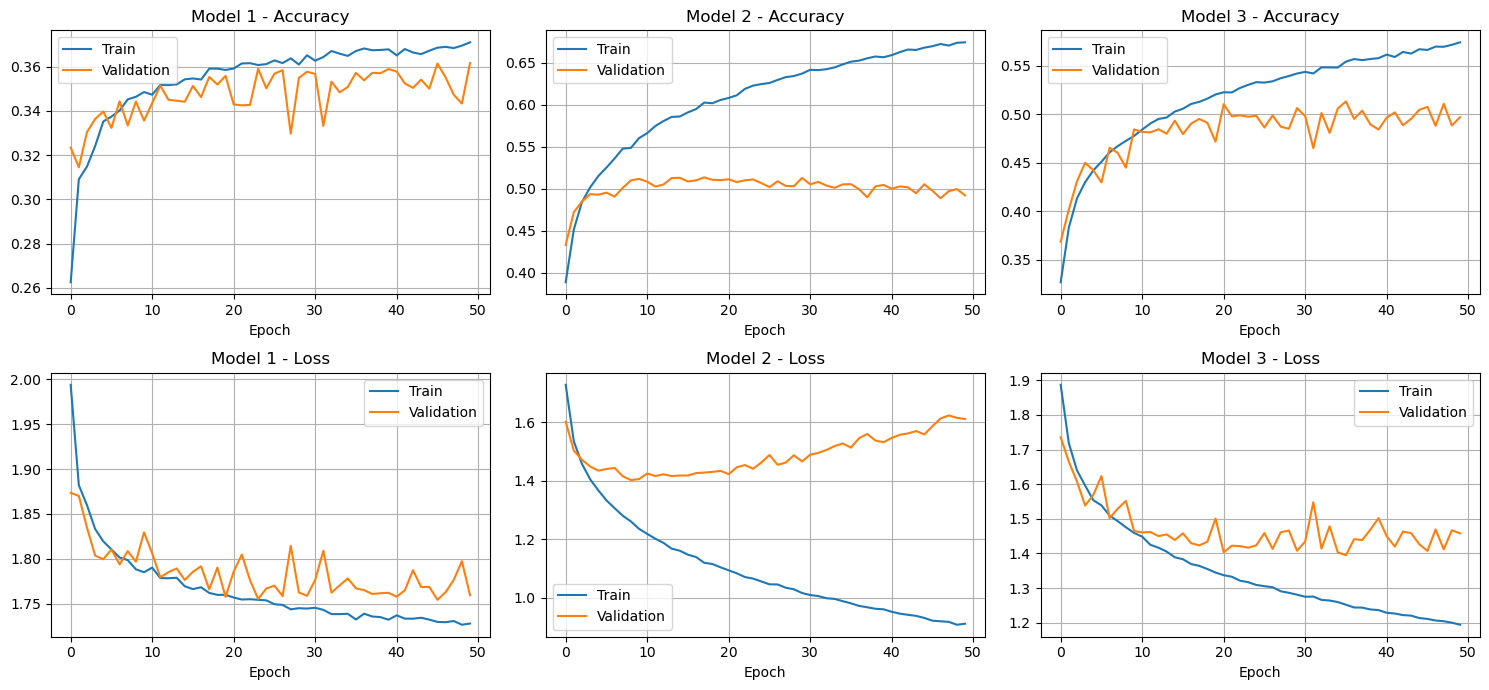

In [ ]:
import matplotlib.pyplot as plt

histories = [history_relu_before_bn, history_relu_after_bn, history_selu]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for i in range(3):
    h = histories[i].history

    axes[0, i].plot(h["accuracy"], label="Train")
    axes[0, i].plot(h["val_accuracy"], label="Validation")
    axes[0, i].set_title(f"Model {i+1} - Accuracy")

    axes[1, i].plot(h["loss"], label="Train")
    axes[1, i].plot(h["val_loss"], label="Validation")
    axes[1, i].set_title(f"Model {i+1} - Loss")

for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

## 6. Visualizing simple convolution filters

Two manually defined 3×3 filters are applied to a few CIFAR-10 images to illustrate how convolution produces feature maps from local image patterns.

In [12]:
import numpy as np
filters = np.zeros((3, 3, 3, 2))
idx = np.arange(3)
filters[idx, idx, :, 0] = 1
filters[idx, 2-idx, :, 1] = 1



In [152]:
images = x_train[:10]

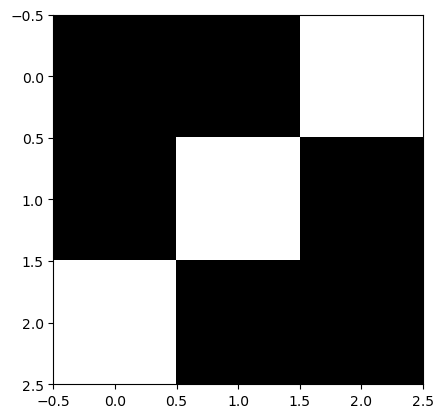

In [13]:
import matplotlib.pyplot as plt
plt.imshow(filters[:, :, :, 1])

In [16]:
convolved_images = tf.nn.conv2d(images, filters, strides=1, padding="SAME")

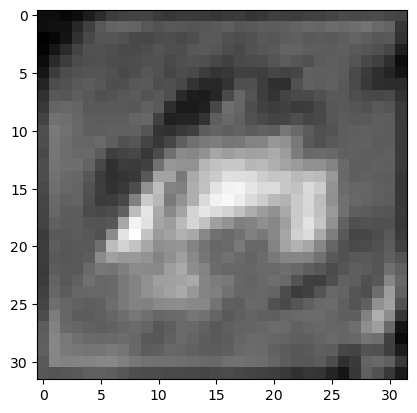

In [ ]:
plt.imshow(convolved_images[0, :, :, 1], cmap="gray")

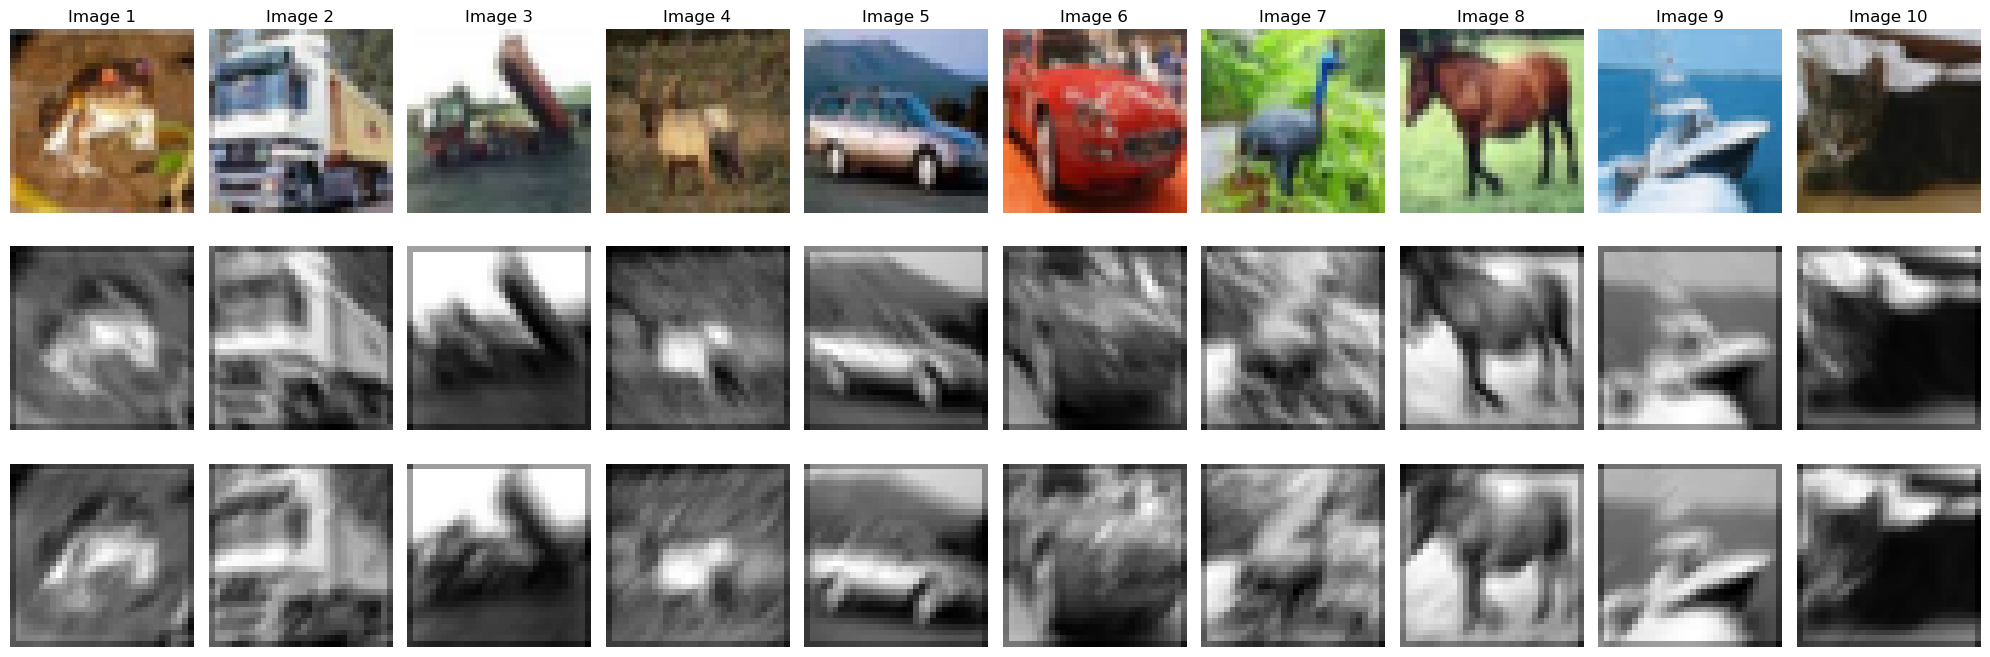

In [17]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10


# 5. Plot original and filtered images
fig, axes = plt.subplots(3, 10, figsize=(20, 7))

for i in range(10):

    # Original image
    axes[0, i].imshow(images[i])
    axes[0, i].set_title(f"Image {i+1}")
    axes[0, i].axis("off")

    # First filter
    axes[1, i].imshow(convolved_images[i, :, :, 0], cmap="gray")
    axes[1, i].axis("off")

    # Second filter
    axes[2, i].imshow(convolved_images[i, :, :, 1], cmap="gray")
    axes[2, i].axis("off")

    

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Main Diagonal")
axes[2, 0].set_ylabel("Anti Diagonal")

plt.tight_layout()
plt.show()

## 7. Custom convolutional neural network

The custom CNN contains six convolutional layers with 3×3 kernels.  
The number of filters increases with depth:

**32 → 32 → 64 → 64 → 128 → 128**

Three max-pooling layers progressively reduce the spatial resolution, and Global Average Pooling converts the final feature maps into a compact vector before the 10-class softmax output.

In [11]:

def build_model_cnn():
    model = keras.Sequential([
        keras.layers.Input(shape=(32,32,3)),

        keras.layers.Conv2D(filters=32, kernel_size=3,activation="relu", kernel_initializer="he_normal" ,padding="same", strides=1), 
        keras.layers.Conv2D(filters=32, kernel_size=3,activation="relu", kernel_initializer="he_normal" ,padding="same", strides=1), 
        keras.layers.MaxPool2D(pool_size=2),

        keras.layers.Conv2D(filters=64, kernel_size=3,activation="relu", kernel_initializer="he_normal" ,padding="same", strides=1), 
        keras.layers.Conv2D(filters=64, kernel_size=3,activation="relu", kernel_initializer="he_normal" ,padding="same", strides=1), 
        keras.layers.MaxPool2D(pool_size=2),

        keras.layers.Conv2D(filters=128, kernel_size=3,activation="relu", kernel_initializer="he_normal" ,padding="same", strides=1), 
        keras.layers.Conv2D(filters=128, kernel_size=3,activation="relu", kernel_initializer="he_normal" ,padding="same", strides=1), 
        keras.layers.MaxPool2D(pool_size=2),

        keras.layers.GlobalAveragePooling2D(),

        keras.layers.Dense(10, activation="softmax")
    ])
    return model

In [ ]:
model1 = build_model_cnn()
model1.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_6 (Conv2D)           (None, 32, 32, 32)        896       
                                                                 
 conv2d_7 (Conv2D)           (None, 32, 32, 32)        9248      
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 16, 16, 32)       0         
 2D)                                                             
                                                                 
 conv2d_8 (Conv2D)           (None, 16, 16, 64)        18496     
                                                                 
 conv2d_9 (Conv2D)           (None, 16, 16, 64)        36928     
                                                                 
 max_pooling2d_4 (MaxPooling  (None, 8, 8, 64)         0         
 2D)                                                  

In [ ]:
callbacks_list = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
             keras.callbacks.ModelCheckpoint(filepath=MODEL_DIR / "best_cnn.keras",
                                              monitor="val_loss", save_best_only=True )]

In [24]:
model1.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])

In [26]:
import time

start_time = time.perf_counter()

history = model1.fit(x_tr, y_tr, validation_data=(x_val, y_val), epochs=50, batch_size=64, verbose=1, callbacks=callbacks_list)

training_time = time.perf_counter() - start_time
print("Training time:", training_time, "seconds")

Epoch 1/50
625/625 [==============================] - 80s 124ms/step - loss: 1.5883 - accuracy: 0.4102 - val_loss: 1.3419 - val_accuracy: 0.5190
Epoch 2/50
625/625 [==============================] - 74s 119ms/step - loss: 1.1451 - accuracy: 0.5893 - val_loss: 1.0268 - val_accuracy: 0.6384
Epoch 3/50
625/625 [==============================] - 80s 128ms/step - loss: 0.9200 - accuracy: 0.6747 - val_loss: 0.8451 - val_accuracy: 0.7065
Epoch 4/50
625/625 [==============================] - 78s 124ms/step - loss: 0.7795 - accuracy: 0.7273 - val_loss: 0.7899 - val_accuracy: 0.7249
Epoch 5/50
625/625 [==============================] - 70s 111ms/step - loss: 0.6602 - accuracy: 0.7702 - val_loss: 0.7248 - val_accuracy: 0.7478
Epoch 6/50
625/625 [==============================] - 68s 109ms/step - loss: 0.5725 - accuracy: 0.7983 - val_loss: 0.6933 - val_accuracy: 0.7636
Epoch 7/50
625/625 [==============================] - 65s 103ms/step - loss: 0.4864 - accuracy: 0.8311 - val_loss: 0.7023 - val_ac

In [ ]:
transfer_model1 = keras.models.load_model(filepath=MODEL_DIR / "best_cnn_transfer.keras")

In [19]:
transfer_model1.evaluate(x_test, y_test)

313/313 [==============================] - 11s 34ms/step - loss: 0.6863 - accuracy: 0.7799


[0.6863347887992859, 0.7799000144004822]

## 8. Frozen-backbone feature reuse — Horse vs. Not-Horse

CIFAR-10 class `7` corresponds to horse.

A balanced binary training dataset is created from the CIFAR-10 training set using:

- 3,000 horse images
- 3,000 non-horse images

The previously trained CNN is reused as a frozen feature extractor. A new sigmoid output layer is trained for binary classification.

A separate balanced binary test set is created from the official CIFAR-10 test split, so final binary evaluation does not reuse training images.

In [ ]:
transfered_model2 = keras.models.load_model(MODEL_DIR / "best_cnn.keras")

In [138]:
horse_tr_idx = np.where(y_train == 7)[0]
not_horse_tr_idx = np.where(y_train != 7)[0]
not_horse_tr_idx

array([    0,     1,     2, ..., 49997, 49998, 49999], dtype=int64)

In [139]:
rng = np.random.default_rng(42)
horse_selected = rng.choice(horse_tr_idx, size=3000, replace=False)
not_horse_selected = rng.choice(not_horse_tr_idx, size=3000, replace=False)

In [140]:
not_horse_selected.shape

(3000,)

In [141]:
selected_idx = np.concatenate([horse_selected, not_horse_selected])
rng.shuffle(selected_idx)

In [142]:
selected_idx.shape

(6000,)

In [143]:
x_binary = x_train[selected_idx]
y_binary = (y_train[selected_idx] == 7).astype(np.int8)

In [144]:
y_binary

array([0, 1, 1, ..., 1, 0, 1], dtype=int8)

In [145]:
x_binary_tr, x_binary_val, y_binary_tr, y_binary_val = train_test_split(x_binary, y_binary, test_size=0.2, random_state=42, stratify=y_binary)

In [146]:
base_model = keras.Model(
    inputs = transfered_model2.inputs,
    outputs = transfered_model2.layers[-2].output
)
base_model.trainable = False


In [147]:
binary_model = keras.models.Sequential([
    base_model,
    keras.layers.Dense(1, activation="sigmoid")])

In [ ]:
callbacks_list_transfer = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
             keras.callbacks.ModelCheckpoint(filepath=MODEL_DIR / "best_cnn_transfer.keras",
                                            monitor="val_loss", save_best_only=True )]

In [149]:
binary_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="binary_crossentropy",
               metrics=["accuracy"])

In [151]:
import time

start_time = time.perf_counter()

history_transfer = binary_model.fit(x_binary_tr,
                            y_binary_tr,
                            validation_data=(x_binary_val, y_binary_val),
                            epochs=50, batch_size=64, 
                            verbose=1, 
                            callbacks=callbacks_list_transfer)
training_time = time.perf_counter() - start_time
print("Training time:", training_time, "seconds")

Epoch 1/50
75/75 [==============================] - 6s 78ms/step - loss: 0.3461 - accuracy: 0.8521 - val_loss: 0.3139 - val_accuracy: 0.8650
Epoch 2/50
75/75 [==============================] - 5s 62ms/step - loss: 0.2747 - accuracy: 0.8896 - val_loss: 0.2657 - val_accuracy: 0.8883
Epoch 3/50
75/75 [==============================] - 4s 53ms/step - loss: 0.2378 - accuracy: 0.9052 - val_loss: 0.2353 - val_accuracy: 0.9033
Epoch 4/50
75/75 [==============================] - 4s 57ms/step - loss: 0.2144 - accuracy: 0.9167 - val_loss: 0.2147 - val_accuracy: 0.9075
Epoch 5/50
75/75 [==============================] - 4s 58ms/step - loss: 0.1981 - accuracy: 0.9256 - val_loss: 0.1995 - val_accuracy: 0.9208
Epoch 6/50
75/75 [==============================] - 5s 62ms/step - loss: 0.1854 - accuracy: 0.9290 - val_loss: 0.1875 - val_accuracy: 0.9258
Epoch 7/50
75/75 [==============================] - 5s 63ms/step - loss: 0.1757 - accuracy: 0.9327 - val_loss: 0.1780 - val_accuracy: 0.9300
Epoch 8/50
75

## 9. Notes for reproducibility

- Random seeds are fixed with `keras.utils.set_random_seed(42)`.
- CIFAR-10 is downloaded through Keras instead of a machine-specific local path.
- Models, histories, and figures are saved with relative project paths.
- The official CIFAR-10 test set is not used as validation data.
- Input images are normalized only once.